In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


df_new = pd.read_csv('/content/NIFTY-30MAY24-30MAY24.csv')

display(df_new.head())
display(df_new.info())

,datetime,strike_price,right,open,high,low,close,open_interest,volume
0,09:26,20050,CE,2600.00,2600.00,2600.0,2600.0,15675,25
1,09:35,20050,CE,2560.50,2573.70,2560.5,2573.7,15675,75
2,09:36,20050,CE,2566.15,2566.15,2557.6,2557.6,15650,75
3,09:37,20050,CE,2548.45,2548.45,2539.4,2539.4,15650,50
4,09:38,20050,CE,2550.30,2550.30,2548.0,2548.0,15650,50


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44717 entries, 0 to 44716
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   datetime       44717 non-null  object 
 1   strike_price   44717 non-null  int64  
 2   right          44717 non-null  object 
 3   open           44717 non-null  float64
 4   high           44717 non-null  float64
 5   low            44717 non-null  float64
 6   close          44717 non-null  float64
 7   open_interest  44717 non-null  int64  
 8   volume         44717 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 3.1+ MB


None

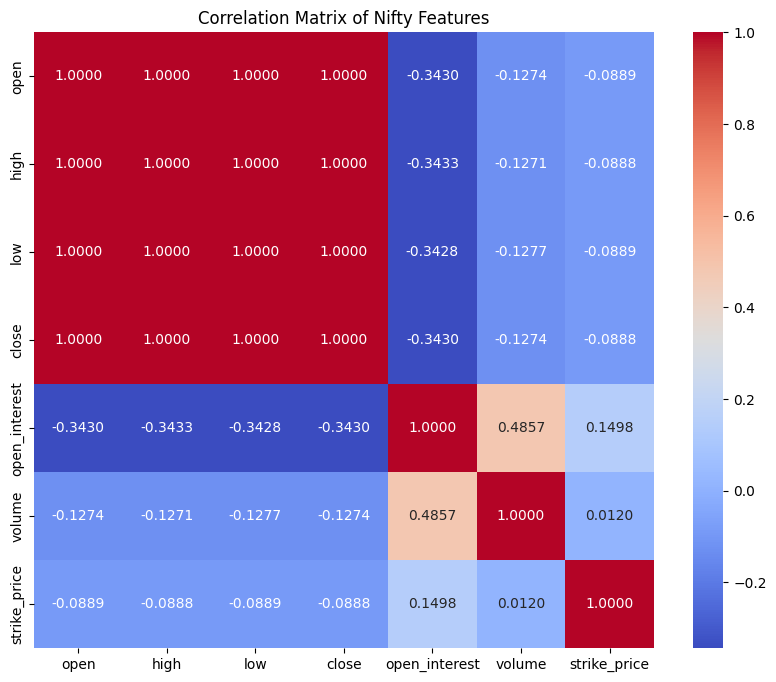

In [4]:

numerical_cols = ['open', 'high', 'low', 'close', 'open_interest', 'volume', 'strike_price']
corr_matrix = df_new[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.4f')
plt.title('Correlation Matrix of Nifty Features')
plt.show()

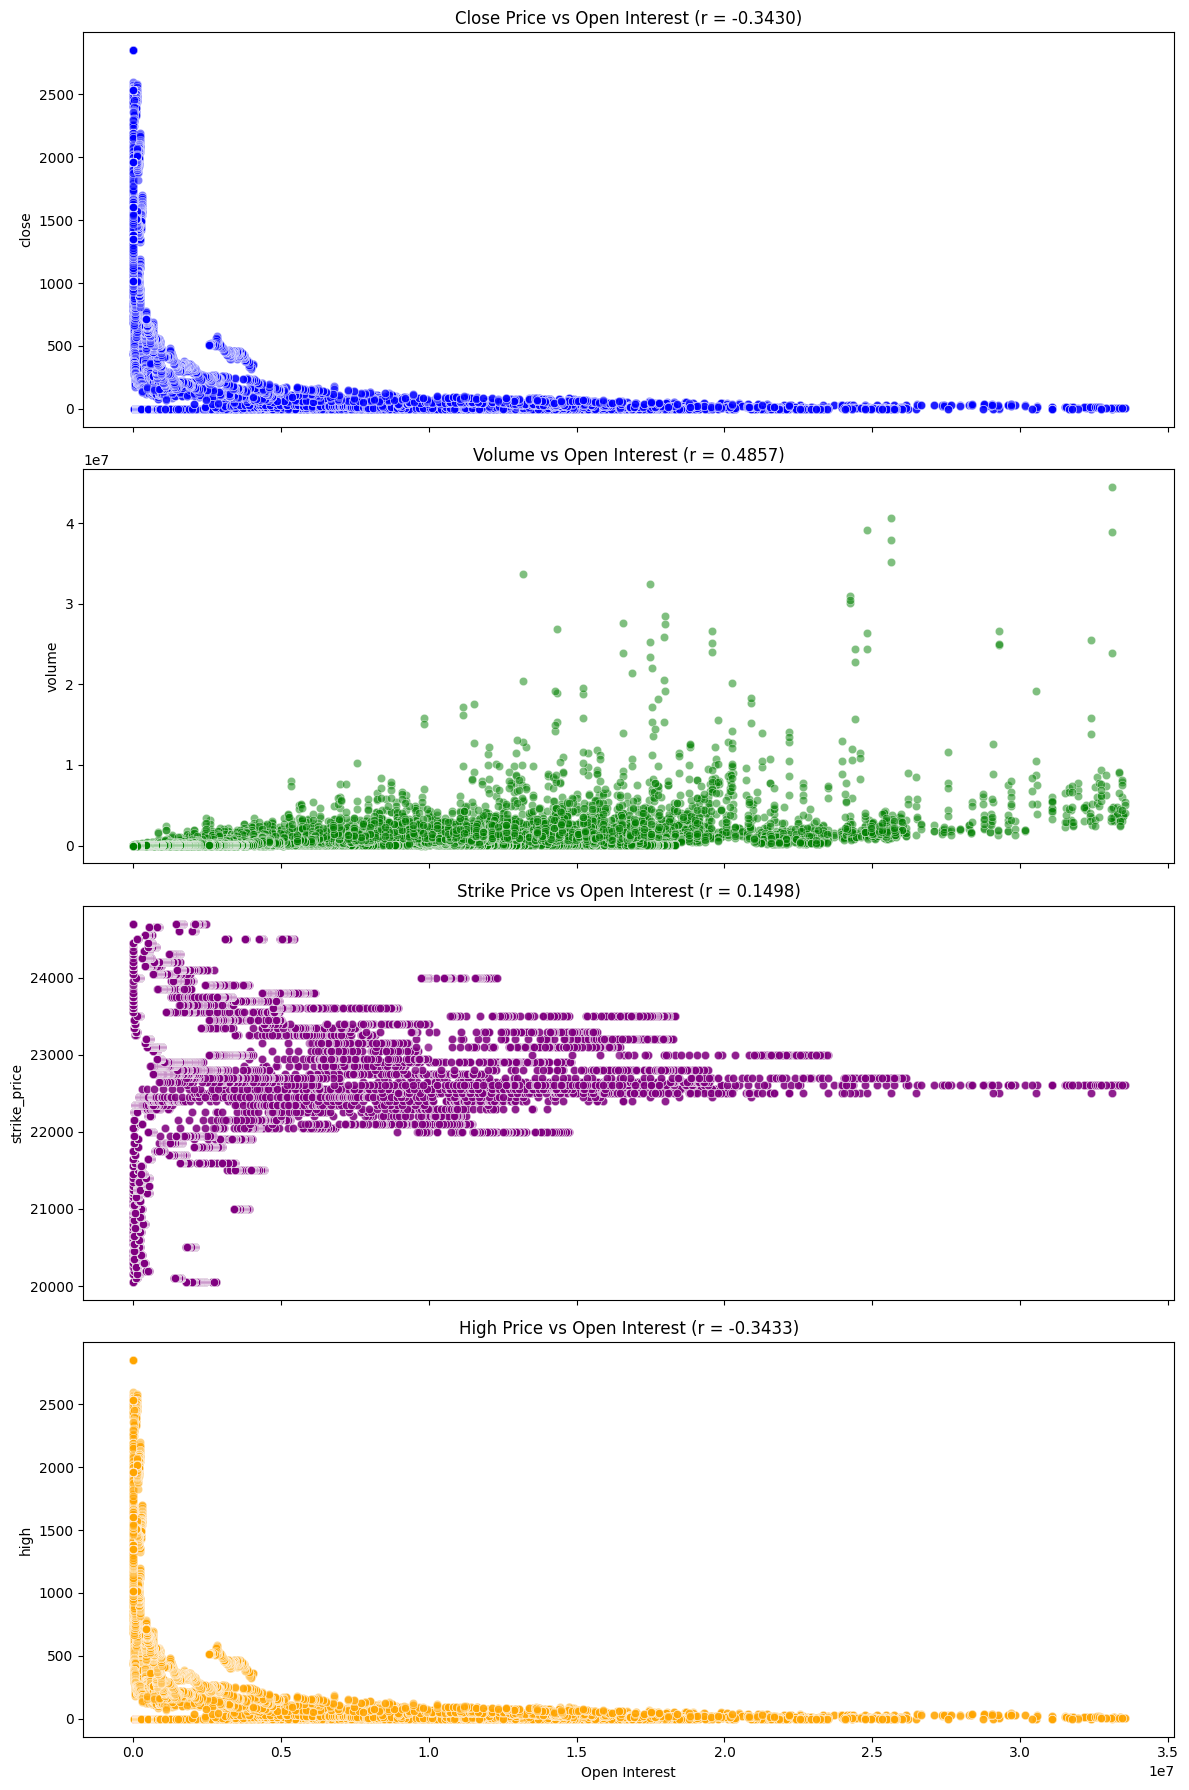

In [5]:

fig, axes = plt.subplots(4, 1, figsize=(12, 18), sharex=True)


targets = [
    ('close', 'blue', 'Close Price vs Open Interest'),
    ('volume', 'green', 'Volume vs Open Interest'),
    ('strike_price', 'purple', 'Strike Price vs Open Interest'),
    ('high', 'orange', 'High Price vs Open Interest')
]

for idx, (col, color, title) in enumerate(targets):
    corr_val = df_new['open_interest'].corr(df_new[col])
    sns.scatterplot(ax=axes[idx], data=df_new, x='open_interest', y=col, alpha=0.5, color=color)
    axes[idx].set_title(f'{title} (r = {corr_val:.4f})')
    axes[idx].set_xlabel('Open Interest')
    axes[idx].set_ylabel(col)

plt.tight_layout()
plt.show()